This tutorial uses KaleCardiac to pretrain, fine-tune, evaluate and interpret CardioVAE [1], a multimodal variational autoencoder (VAE) for two modalities: the chest X-ray (CXR) and the twelve-lead electrocardiogram (ECG).

CardioVAE learns a shared latent representation of both modalities from paired, unlabelled ECGs and CXRs. Its *tri-stream* objective combines three evidence lower bounds (ELBOs): one through both modalities together and one through each modality alone, so that each encoder remains useful when the other modality is missing. The modalities are fused at the feature-embedding level (intermediate fusion), and a classifier is then fine-tuned on top of the pretrained encoders.

The workflow starts from raw DICOM files, the format in which hospitals export ECGs and chest X-rays, and each step takes a few calls to the KaleCardiac API:

- **Step 0: Environment preparation.** Install KaleCardiac and download the tutorial dataset.
- **Step 1: Multimodal pretraining.** Load the pretraining configuration, load and prepare the unlabelled ECG–CXR pairs, then pretrain CardioVAE.
- **Step 2: Multimodal fine-tuning.** Load the fine-tuning configuration, load and prepare the labelled pairs, then fine-tune a classifier.
- **Step 3: Evaluation.** Score the held-out test subjects.
- **Step 4: Interpretation.** Identify which modality, and which regions of each ECG and CXR, the predictions rely on.

**Estimated runtime:** about 10 minutes on a Colab T4 GPU, including installation. The estimates for individual steps below also refer to a T4 GPU.

## Step 0: Environment Preparation

### Runtime

In Google Colab, select **Runtime > Change runtime type > T4 GPU**. The tutorial also runs on a CPU, more slowly.

### Package installation

The cell below installs KaleCardiac from its GitHub repository with two optional extras: `imaging` (pydicom and scikit-image, required by PyKale's DICOM reader) and `interpret` (Captum, for integrated gradients). pip also installs the other dependencies the tutorial needs, such as PyKale and PyTorch Lightning. The cell then downloads this tutorial's folder, containing the notebook and its `configs`, and makes it the working directory.

Run this cell in Google Colab. When running locally, skip it: install KaleCardiac with `pip install -e ".[imaging,interpret]"` from a clone of its repository, and open the notebook from a folder that contains its `configs` folder, such as `tutorials/mdas_tutorial`.

**Estimated runtime:** 3 minutes

In [ ]:
!pip install --quiet "kalecardiac[imaging,interpret] @ git+https://github.com/pykale/cardiac@main"
!git clone --quiet --depth 1 --filter=blob:none --sparse https://github.com/pykale/cardiac
!git -C cardiac sparse-checkout set tutorials/mdas_tutorial
%cd cardiac/tutorials/mdas_tutorial

### Setup

The cell below silences warnings and PyTorch Lightning's start-up messages to keep the output readable, then reports the installed KaleCardiac version and the working directory, confirming that the installation succeeded.

In [1]:
import logging
import warnings
from pathlib import Path

import pytorch_lightning

import kalecardiac

warnings.filterwarnings("ignore")
# Importing Lightning sets its loggers' level, so they are quieted after it is imported.
for name in (pytorch_lightning.__name__, "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.ERROR)
print(f"KaleCardiac {kalecardiac.__version__}, working in {Path.cwd()}")

KaleCardiac 0.1.0a0, working in M:\cardiac\tutorials\mdas_tutorial


### Dataset download

The tutorial dataset is a single ZIP archive. The cell below downloads it into the runtime's local storage, without any sign-in, and unpacks it into `data/` next to this notebook:

```
data/
├── kalecardiac_pretraining/
│   ├── ECG/<subject>/.../*.dcm    one twelve-lead ECG per subject (DICOM ECG waveform)
│   └── CXR/<subject>/.../*.dcm    one chest X-ray per subject (DICOM radiograph)
└── kalecardiac_finetuning/
    ├── ECG/<subject>/.../*.dcm
    ├── CXR/<subject>/.../*.dcm
    └── labels.csv                 subject_id,label
```

`kalecardiac_pretraining` holds unlabelled ECG–CXR pairs for pretraining; `kalecardiac_finetuning` adds a label for each subject for fine-tuning. As in a hospital export, each subject has a folder named by its identifier, and a subject's ECG and CXR are paired by that name. To use your own data instead, skip this cell and see *Your own data* below.

**Estimated runtime:** 1 minute

In [2]:
import urllib.request
import zipfile

# The tutorial dataset on Dropbox; "dl=1" asks Dropbox for the file itself rather than its web page.
DATA_URL = "https://www.dropbox.com/scl/fi/y488iouenrk641dxtd8ai/kalecardiac_tutorial_data.zip?rlkey=rorf5mvbt24jdw2cr3ecyy91n&st=yt83r37g&dl=1"

if not Path("data").is_dir():
    archive, _ = urllib.request.urlretrieve(DATA_URL, "kalecardiac_tutorial_data.zip")
    with zipfile.ZipFile(archive) as bundle:
        bundle.extractall("data")
print(sorted(folder.name for folder in Path("data").iterdir()))

['kalecardiac_finetuning', 'kalecardiac_pretraining']


### Your own data

The same steps run on your own ECGs and chest X-rays, organised as in the tutorial dataset: `ECG/` and `CXR/` folders, each with one folder per subject containing that subject's DICOM file, and, for fine-tuning, a `labels.csv` file with a `subject_id` column and a column of classes (0 or 1). Skip the dataset download, and set your folders in the configuration cells of Step 1 and Step 2 by uncommenting the lines marked *Your own data*. Sampling rates are read from the DICOM headers, and recordings are resampled to the 500 Hz that CardioVAE reads.

Use identifiable patient data only in an approved, secure environment, never on public services such as Colab.

## Step 1: Multimodal Pretraining

CardioVAE is pretrained without labels on the paired ECGs and CXRs in `kalecardiac_pretraining`.

### Configuration

KaleCardiac reads every setting from a [YACS](https://github.com/rbgirshick/yacs) configuration, which keeps an experiment's settings separate from its code. The tutorial's configuration files are in its `configs` folder, and each is merged onto KaleCardiac's defaults (`kalecardiac.config`). Pretraining reads `configs/config_cardiovae_pretrain.yaml`: the unlabelled dataset, the ECG and CXR input shapes (including the order of the ECG leads), the latent width, the tri-stream objective and the pretraining schedule.

Change a setting in the file, or override it in the cell below.

In [3]:
from kalecardiac.config import get_cfg_defaults

cfg_pt = get_cfg_defaults()
cfg_pt.merge_from_file("configs/config_cardiovae_pretrain.yaml")

# ------ Hyperparameters to play with -----
cfg_pt.MODEL.LATENT_DIM = 128
cfg_pt.SOLVER.MAX_EPOCHS = 10
cfg_pt.SOLVER.BATCH_SIZE = 4
cfg_pt.OBJECTIVE.RECONSTRUCTION_WEIGHTS = ["ecg:10", "cxr:1"]
cfg_pt.OBJECTIVE.ANNEALING_EPOCHS = cfg_pt.SOLVER.MAX_EPOCHS  # the KL weight rises over the whole run

# ------ Your own data -----
# cfg_pt.DATASET.ROOT = "/path/to/your/pretraining_data"  # holds ECG/ and CXR/

print(f"DATASET.ROOT: {cfg_pt.DATASET.ROOT}\n")
for section in ("ECG", "IMAGE", "OBJECTIVE", "SOLVER"):
    print(f"{section}:\n{cfg_pt[section]}\n")

DATASET.ROOT: data/kalecardiac_pretraining

ECG:
ENCODER: conv
LEADS: ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
LENGTH: 60000
NORMALIZE: True
NUM_CHANNELS: 1
SAMPLING_RATE: 500
SOURCE_SAMPLING_RATE: 0

IMAGE:
CHANNELS: 1
SCALE: True
SIZE: [224, 224]

OBJECTIVE:
ALIGNMENT_WEIGHT: 0.0
ANNEALING_EPOCHS: 10
POS_WEIGHT: 0.0
RECONSTRUCTION_WEIGHTS: ['ecg:10', 'cxr:1']
SCALE_FACTOR: 0.0001
UNIMODAL_STREAMS: True

SOLVER:
ACCELERATOR: auto
BASE_LR: 0.001
BATCH_SIZE: 4
DEVICES: auto
EARLY_STOP: 0
GRAD_CLIP: 1.0
MAX_EPOCHS: 10
OPTIMIZER: Adam
SEED: 123
WEIGHT_DECAY: 0.0



### Data loading

`ECGFileSource.from_dicom` and `ImageFileSource.from_dicom`, in `kalecardiac.loaddata`, index each modality's folder by subject and read a subject's file only when it is needed, so cohorts of any size load in the same way. Each file is read with PyKale's [3] DICOM reader, [`kale.loaddata.image_access.read_dicom_phases`](https://github.com/pykale/pykale/blob/main/kale/loaddata/image_access.py), and then:

- **ECG:** the twelve-lead rhythm waveform is extracted in millivolts, with each lead's name and the sampling rate read from the file's header. Leads are matched by *name*, so a file that stores aVF before aVL cannot transpose them.
- **CXR:** the pixel values are mapped through the display settings in the file's header (the rescale, the window and, for `MONOCHROME1` images, the inversion), so the model sees the image as a clinician does.

**Estimated runtime:** 10 seconds

In [4]:
from kalecardiac.loaddata import ECGFileSource, ImageFileSource

ecg_dir_pt, cxr_dir_pt = Path(cfg_pt.DATASET.ROOT, "ECG"), Path(cfg_pt.DATASET.ROOT, "CXR")
ecg_raw = ECGFileSource.from_dicom(ecg_dir_pt)
cxr_raw = ImageFileSource.from_dicom(cxr_dir_pt)
print(ecg_raw, cxr_raw, sep="\n")

ECGFileSource(20 subjects | leads=['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'] | shape=12x5120 | 500 Hz)
ImageFileSource(20 subjects | 1x2634x2643)


One subject's ECG and CXR as loaded: lead II of the full recording, and the radiograph at its original resolution.

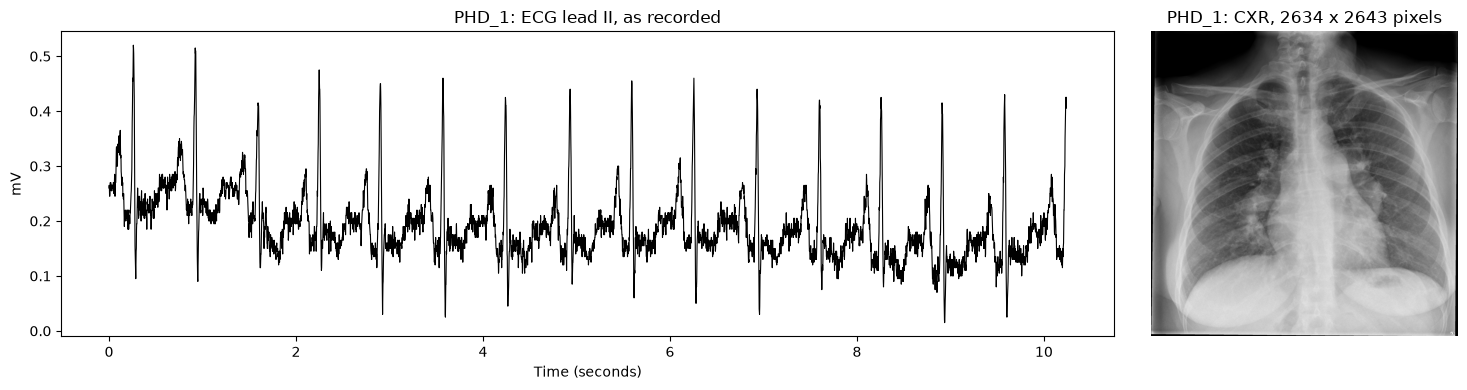

In [5]:
import matplotlib.pyplot as plt
import numpy as np

subject = sorted(ecg_raw.paths)[0]
recording, radiograph = ecg_raw.get(subject, 0).numpy(), cxr_raw.get(subject, 0).numpy()[0]

fig, (ax_ecg, ax_cxr) = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
time = np.arange(recording.shape[1]) / ecg_raw.sampling_rate
ax_ecg.plot(time, recording[ecg_raw.leads.index("II")], color="black", linewidth=0.8)
ax_ecg.set(xlabel="Time (seconds)", ylabel="mV", title=f"{subject}: ECG lead II, as recorded")
ax_cxr.imshow(radiograph, cmap="gray")
ax_cxr.set_title(f"{subject}: CXR, {radiograph.shape[0]} x {radiograph.shape[1]} pixels")
ax_cxr.axis("off")
plt.tight_layout()
plt.show()

### Data preparation

For each subject, CardioVAE reads ten seconds of the twelve-lead ECG recorded at 500 Hz, which gives 5,000 time points per lead, and a 224 × 224 CXR scaled to [0, 1]. The twelve leads are interleaved time point by time point into a single strip of 60,000 values (12 leads × 5,000 time points). Two KaleCardiac transforms build these inputs from the configuration:

- `get_ecg_transform_from_cfg` (`kalecardiac.auto`) reads `cfg.ECG`: it fills any missing values in the signal, resamples a recording made at another rate to 500 Hz, crops or pads each lead to ten seconds, normalizes each lead to zero mean and unit variance, and then interleaves the leads. Every step before the interleaving works on one lead at a time. The leads are taken by name, in the order of `ECG.LEADS`: the order in which the published CardioVAE was pretrained, with aVF before aVL.
- `get_image_transform` (`kalecardiac.prepdata`) resizes the CXR with anti-aliasing and scales it to [0, 1].

The sources apply these transforms as each subject is read. `MultimodalDataset` then pairs the two modalities by subject: each subject yields its ECG as `ecg` and its CXR as `cxr`, the names used by the objective's weights and the model's encoders.

**Estimated runtime:** 10 seconds

In [6]:
from kalecardiac.auto import get_ecg_transform_from_cfg
from kalecardiac.loaddata import MultimodalDataset
from kalecardiac.prepdata import get_image_transform

# The rate the recordings were made at, as their DICOM headers state it, so any other is resampled.
cfg_pt.ECG.SOURCE_SAMPLING_RATE = ecg_raw.sampling_rate
ecg_transform = get_ecg_transform_from_cfg(cfg_pt)
cxr_transform = get_image_transform(size=cfg_pt.IMAGE.SIZE)

ecg = ECGFileSource.from_dicom(ecg_dir_pt, select=cfg_pt.ECG.LEADS, transform=ecg_transform)
cxr = ImageFileSource.from_dicom(cxr_dir_pt, transform=cxr_transform)
pretrain_set = MultimodalDataset(sorted(ecg.paths.keys() & cxr.paths.keys()), {"ecg": ecg, "cxr": cxr})

print(pretrain_set)
print({name: tuple(value.shape) for name, value in pretrain_set[0].modalities.items()})

MultimodalDataset(20 subjects | ecg=ECGFileSource, cxr=ImageFileSource)


{'ecg': (1, 60000), 'cxr': (1, 224, 224)}


### Multimodal pretraining

`CardioVAE`, in `kalecardiac.model.embed`, has an encoder and a decoder for each modality: a 1-D convolutional network for the ECG strip and a 2-D convolutional network for the CXR. It fuses the modalities with a **product of experts**: each encoder's Gaussian over the shared latent space and a standard-normal prior are multiplied into one joint posterior, and a subject missing a modality contributes no expert for it. The input sizes are taken from the prepared data.

`pretrain`, in `kalecardiac.auto`, trains the model with the configured objective (the tri-stream ELBO, with the ECG's reconstruction weighted ten times the CXR's and the KL term annealed in) and saves the weights to `pretrained.pt` in `OUTPUT.OUT_DIR`. Pretraining is a reconstruction task, so it needs no labels.

**Estimated runtime:** 1 to 2 minutes

In [7]:
import pandas as pd

from kalecardiac.auto import pretrain
from kalecardiac.model.embed import CardioVAE
from kalecardiac.utils import set_seed

set_seed(cfg_pt.SOLVER.SEED)
model = CardioVAE(
    signal_length=ecg.length,
    image_size=cxr.size,
    latent_dim=cfg_pt.MODEL.LATENT_DIM,
    signal_name="ecg",
    image_name="cxr",
)
print(f"CardioVAE with {sum(parameter.numel() for parameter in model.parameters()):,} parameters")

pretrained = pretrain(cfg_pt, model, pretrain_set, cfg_pt.OUTPUT.OUT_DIR)

# The training loss per epoch, from the run's log.
log = max(Path(cfg_pt.OUTPUT.OUT_DIR).glob("pretrain/history/*/metrics.csv"), key=lambda path: path.stat().st_mtime)
pd.read_csv(log).groupby("epoch")["train_loss"].mean().round(1).to_frame("training loss").T

CardioVAE with 204,180,418 parameters


epoch,0,1,2,3,4,5,6,7,8,9
training loss,560.0,515.6,398.1,224.4,190.0,182.4,181.5,181.0,180.8,180.4


## Step 2: Multimodal Fine-tuning

The pretrained encoders are fine-tuned on the labelled pairs in `kalecardiac_finetuning` to classify each subject: **0** healthy, **1** cardiothoracic abnormality.

### Configuration

Fine-tuning starts from the pretrained model, so its configuration file, `configs/config_cardiovae_finetune.yaml`, is merged onto the pretraining configuration. It adds the labelled dataset, the endpoint, the train/validation/test split and the fine-tuning schedule.

Change a setting in the file, or override it in the cell below.

In [8]:
# Fine-tuning starts from the pretrained model, and so from its configuration.
cfg_ft = cfg_pt.clone()
cfg_ft.merge_from_file("configs/config_cardiovae_finetune.yaml")

# ------ Hyperparameters to play with -----
cfg_ft.FINETUNE.MAX_EPOCHS = 20
cfg_ft.FINETUNE.BATCH_SIZE = 4
cfg_ft.MODEL.HEAD_HIDDEN = [128]

# ------ Your own data -----
# cfg_ft.DATASET.ROOT = "/path/to/your/finetuning_data"  # holds ECG/, CXR/ and labels.csv
# cfg_ft.ENDPOINT.LABEL_COLUMN = "label"  # the column of labels.csv holding each subject's class

print(f"DATASET.ROOT: {cfg_ft.DATASET.ROOT}")
print(f"ENDPOINT: {cfg_ft.ENDPOINT.NAME}, the {cfg_ft.ENDPOINT.LABEL_COLUMN!r} column of labels.csv\n")
print(f"FINETUNE:\n{cfg_ft.FINETUNE}")

DATASET.ROOT: data/kalecardiac_finetuning
ENDPOINT: cardiothoracic_abnormality, the 'label' column of labels.csv

FINETUNE:
BASE_LR: 0.001
BATCH_SIZE: 4
MAX_EPOCHS: 20


### Data loading

The labelled cohort has the pretraining layout plus `labels.csv`, with one row per subject. Its ECGs and CXRs load through the same DICOM sources and transforms, because the pretrained encoders expect exactly these input shapes; the labels are an ordinary table.

**Estimated runtime:** 1 second

In [9]:
ecg_ft = ECGFileSource.from_dicom(Path(cfg_ft.DATASET.ROOT, "ECG"), select=cfg_pt.ECG.LEADS, transform=ecg_transform)
cxr_ft = ImageFileSource.from_dicom(Path(cfg_ft.DATASET.ROOT, "CXR"), transform=cxr_transform)
labels = pd.read_csv(Path(cfg_ft.DATASET.ROOT, "labels.csv"))

print(ecg_ft, cxr_ft, sep="\n")
labels.head()

ECGFileSource(20 subjects | leads=['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'] | shape=1x60000 | 500 Hz)


ImageFileSource(20 subjects | 1x224x224)


,subject_id,label
0,PHD_1,0
1,PHD_2,1
2,PHD_3,0
3,PHD_4,1
4,PHD_5,0


### Data preparation

Three calls, each reading `cfg_ft`, turn the labels into a fine-tuning task:

- `derive_endpoint` reads each subject's class from `ENDPOINT.LABEL_COLUMN`, dropping a subject without a label rather than assuming it is negative.
- `get_endpoint_target` makes the class the supervision target that every batch carries.
- `get_folds` divides the subjects into training, validation and test sets, stratified by label, with no subject in two sets. 20% of the subjects are held out for testing, and the validation set that selects the checkpoint is drawn from the rest, never from the test set.

The class weight used by the loss is computed from the training set alone.

**Estimated runtime:** 1 second

In [10]:
from kalecardiac.auto import derive_endpoint, get_endpoint_target, get_folds

table = derive_endpoint(cfg_ft, labels)
target = get_endpoint_target(cfg_ft, table, id_column="subject_id")
fold = get_folds(cfg_ft, table)[0]
print(
    f"{len(fold.train_ids)} subjects to train on, {len(fold.val_ids)} to validate on, {len(fold.test_ids)} to test on"
)

13 subjects to train on, 3 to validate on, 4 to test on


### Multimodal fine-tuning

`fine_tune`, in `kalecardiac.auto`, keeps the pretrained CardioVAE encoders frozen as feature extractors and trains a classification head on the concatenated posterior means of both modalities. The head, the loss and the positive class's weight follow from the endpoint and the training labels. After training, the checkpoint with the best validation score is restored and the test subjects are scored.

**Estimated runtime:** 1 to 2 minutes

In [11]:
from kalecardiac.auto import fine_tune

set_seed(cfg_ft.SOLVER.SEED)
result = fine_tune(cfg_ft, pretrained, {"ecg": ecg_ft, "cxr": cxr_ft}, target, fold, cfg_ft.OUTPUT.OUT_DIR)

## Step 3: Evaluation

`fine_tune` scores the held-out test subjects with `score_predictions`, which chooses the metrics suited to the endpoint; for a binary endpoint, these come from `binary_metrics` in `kalecardiac.evaluate`:

- **Accuracy:** the proportion of subjects classified correctly.
- **AUROC:** the area under the receiver operating characteristic curve, which measures how well the scores rank positive subjects above negative ones across all thresholds.
- **MCC:** the Matthews correlation coefficient, which remains informative when the classes are imbalanced.
- **Sensitivity** and **specificity:** the proportions of positive and of negative subjects classified correctly.

AUROC does not depend on a decision threshold, whereas accuracy, MCC, sensitivity and specificity are computed at a threshold of 0.5, so a model can rank subjects well while its scores still fall on one side of that threshold. The predictions are kept for each subject, so they can be inspected or scored again at another threshold.

In [12]:
metrics = pd.Series(result.metrics)[["accuracy", "roc_auc", "mcc", "sensitivity", "specificity"]].astype(float)
metrics.rename({"roc_auc": "AUROC", "mcc": "MCC"}).round(3).to_frame("test")

,test
accuracy,0.5
AUROC,1.0
MCC,0.0
sensitivity,0.0
specificity,1.0


In [13]:
predictions = pd.DataFrame(result.predictions.rows())
predictions.assign(probability=1 / (1 + np.exp(-predictions["score"]))).round(3)

,subject_id,split,fold,score,label,probability
0,PHD_13,test,0,-0.599,0.0,0.355
1,PHD_15,test,0,-0.384,1.0,0.405
2,PHD_6,test,0,-0.384,1.0,0.405
3,PHD_7,test,0,-0.544,0.0,0.367


## Step 4: Interpretation

Two questions, both answered from the fine-tuned model:

- **Which modality does the model rely on?** `interpret_model`, in `kalecardiac.auto`, runs integrated gradients over the test subjects and reports each modality's *attribution ratio*: the share of its ECG time points or CXR pixels that are strongly attributed. It then withholds each modality in turn, through the presence mask, and scores the test set again; a modality whose removal costs little is one the model can do without.
- **Where in each modality?** `modality_attributions`, in `kalecardiac.interpret`, attributes one subject's prediction to every time point of its ECG and every pixel of its CXR with [Captum](https://captum.ai)'s integrated gradients [2], and `normalize_attribution` rescales each map to [0, 1], so that the regions above a threshold can be highlighted.

**Estimated runtime:** 10 seconds

In [14]:
from kalecardiac.auto import interpret_model

summary = interpret_model(cfg_ft, result.model, result.test_loader, cfg_ft.OUTPUT.OUT_DIR)
pd.DataFrame(summary["attribution"]).T.round(3)

,ratio,share
ecg,0.922,0.61
cxr,0.590,0.39


The test AUROC with every modality, and with each modality withheld:

In [15]:
pd.Series(summary.get("ablation", {}), name="test AUROC").round(3).to_frame()

,test AUROC
full,1.0
without_ecg,0.5
drop_ecg,0.5
without_cxr,1.0
drop_cxr,0.0


One test subject's prediction, attributed to its ECG and CXR. The ECG strip interleaves the twelve leads, so a single lead is read out of it by name.

In [16]:
import torch

from kalecardiac.interpret import modality_attributions, normalize_attribution
from kalecardiac.loaddata import collate_subjects

# Change these to explain another test subject or lead, or to move the thresholds.
SAMPLE_IDX, LEAD = 0, "II"
ECG_THRESHOLD, CXR_THRESHOLD, ZOOM_RANGE = 0.75, 0.75, (3.5, 4.0)

sample = collate_subjects([result.test_loader.dataset[SAMPLE_IDX]])
attributions = modality_attributions(result.model.model, sample.modalities, present=sample.present)

# The strip interleaves the leads time point by time point: one row per time point, one column per lead.
lead, num_leads = ecg_ft.leads.index(LEAD), len(ecg_ft.leads)
ecg_signal = sample.modalities["ecg"][0, 0].numpy().reshape(-1, num_leads)[:, lead]
ecg_importance = normalize_attribution(attributions["ecg"][0, 0]).reshape(-1, num_leads)[:, lead]
ecg_time = np.arange(ecg_signal.size) / cfg_ft.ECG.SAMPLING_RATE
cxr_image = sample.modalities["cxr"][0, 0].numpy()
cxr_importance = normalize_attribution(attributions["cxr"][0, 0])

probability = torch.sigmoid(result.model.predict(sample).prediction).item()
print(
    f"{sample.subject_id[0]}: label {int(sample.target['label'])}, predicted probability of a cardiothoracic "
    f"abnormality {probability:.2f}"
)

PHD_13: label 0, predicted probability of a cardiothoracic abnormality 0.35


**Full ECG view:** the full ten seconds of one lead, with the time points whose attribution exceeds the threshold drawn in red.

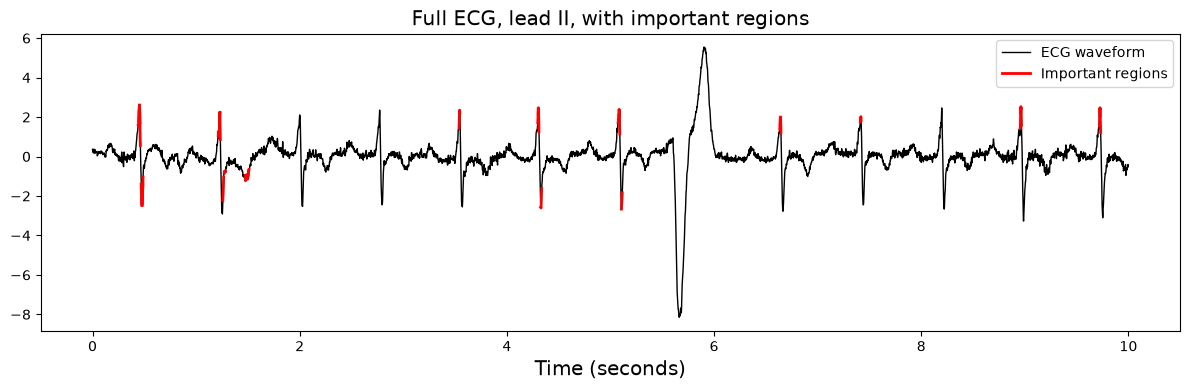

In [17]:
def plot_ecg(window: slice, title: str, width: float = 1.0):
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(ecg_time[window], ecg_signal[window], color="black", linewidth=width)
    for index in np.flatnonzero(ecg_importance[window] >= ECG_THRESHOLD):
        stretch = slice(max(index - 2, 0), index + 3)
        ax.plot(ecg_time[window][stretch], ecg_signal[window][stretch], color="red", linewidth=2 * width)
    ax.set_xlabel("Time (seconds)", fontsize="x-large")
    ax.set_title(title, fontsize="x-large")
    ax.legend(["ECG waveform", "Important regions"], fontsize="medium")
    plt.tight_layout()
    plt.show()


plot_ecg(slice(None), f"Full ECG, lead {LEAD}, with important regions")

**Zoomed-in ECG segment:** a short stretch of the same lead, 3.5 to 4.0 seconds by default, in finer detail.

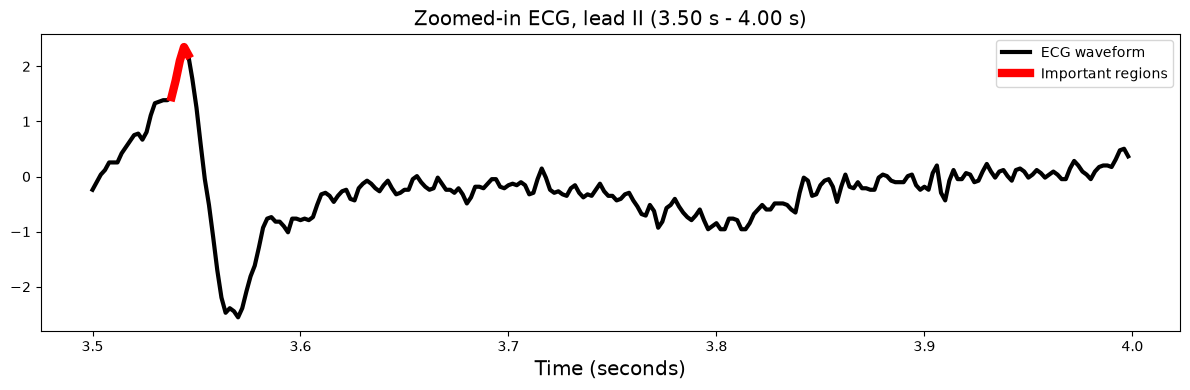

In [18]:
first, last = ZOOM_RANGE
window = slice(int(first * cfg_ft.ECG.SAMPLING_RATE), int(last * cfg_ft.ECG.SAMPLING_RATE))
plot_ecg(window, f"Zoomed-in ECG, lead {LEAD} ({first:.2f} s - {last:.2f} s)", width=3)

**CXR attribution map:** the pixels whose attribution exceeds the threshold, marked on the radiograph and coloured by their importance.

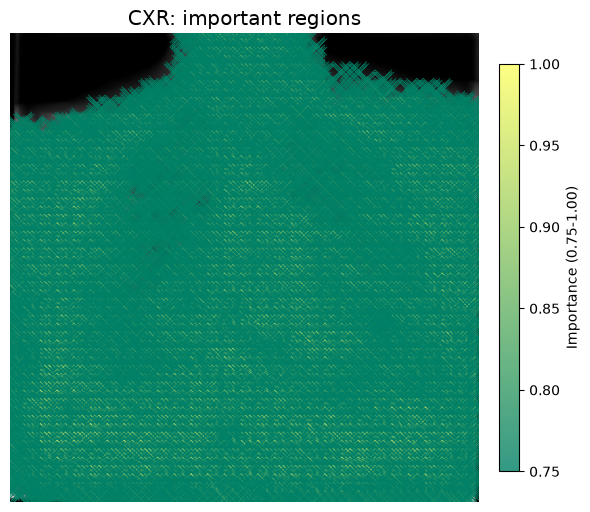

In [19]:
from scipy.ndimage import binary_dilation

y_points, x_points = np.where(binary_dilation(cxr_importance >= CXR_THRESHOLD, iterations=1))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(cxr_image, cmap="gray")
points = ax.scatter(
    x_points,
    y_points,
    c=cxr_importance[y_points, x_points],
    cmap="summer",
    marker="x",
    s=150,
    vmin=CXR_THRESHOLD,
    vmax=1.0,
    alpha=0.8,
    linewidths=0.7,
)
plt.colorbar(points, ax=ax, fraction=0.04, pad=0.04).set_label(f"Importance ({CXR_THRESHOLD:.2f}-1.00)")
ax.axis("off")
ax.set_title("CXR: important regions", fontsize="x-large")
plt.tight_layout()
plt.show()

## Where next

- The [CardioVAE example](https://github.com/pykale/cardiac/tree/main/examples/cardiovae_multimodal) runs this model from the command line, with cross-validation, modality ablation and a written report: `python -m examples.cardiovae_multimodal.main --cfg <your config>`.
- The LS-EMVAE tutorial, `tutorial-LSEMVAE.ipynb`, treats each ECG lead as a modality of its own; the [LS-EMVAE example](https://github.com/pykale/cardiac/tree/main/examples/lsemvae_ecg) runs it from the command line.
- The [API overview](https://github.com/pykale/cardiac/blob/main/API_overview.md) lists every stage of the KaleCardiac API.

## References

[1] Suvon, M. N., Tripathi, P. C., Fan, W., Zhou, S., Liu, X., Alabed, S., ... & Lu, H. (2024). Multimodal variational autoencoder for low-cost cardiac hemodynamics instability detection. In *International Conference on Medical Image Computing and Computer-Assisted Intervention* (pp. 296-306).

[2] Sundararajan, M., Taly, A., & Yan, Q. (2017). Axiomatic attribution for deep networks. In *International Conference on Machine Learning* (pp. 3319-3328).

[3] Lu, H., Liu, X., Zhou, S., Turner, R., Bai, P., Koot, R. E., ... & Xu, H. (2022). PyKale: Knowledge-aware machine learning from multiple sources in Python. In *Proceedings of the 31st ACM International Conference on Information & Knowledge Management* (pp. 4274-4278).